## Image Segmentation Dataset Creation
This notebook demonstrates how to create a **custom dataset class** to load 2D image slices and their corresponding segmentation masks. It also includes augmentation techniques for data preprocessing during training.

---

### 1. Importing Libraries
We start by importing essential libraries.

In [ ]:
# !pip install numpy==1.26.3
# !pip install imgaug

# If you have an NVIDIA GPU, install PyTorch following the instructions at:
# https://pytorch.org/get-started/locally/
# Otherwise, install the CPU version with the command below.
#!pip3 install torch torchvision torchaudio

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset
import random

import imgaug
import imgaug.augmenters as iaa
from imgaug.augmentables.segmaps import SegmentationMapsOnImage

---
### 2. Defining Paths
Here, we define the directories for the training and validation datasets.

In [2]:
root_dir = "data/processed/preprocessed_ircadb_liver_dataset"

train_dir = os.path.join(root_dir, "train")
val_dir = os.path.join(root_dir, "val")

---
### 3. Extracting Image and Label Paths
This function collects all image slices and their corresponding label files from the directories provided.

In [3]:
def get_image_and_label_paths(src_dir):
    """Extract image and corresponding label file paths from the source directory."""
    image_paths = []
    label_paths = []

    subjects = os.listdir(src_dir)

    for subject in subjects:
        image_dir = os.path.join(src_dir, subject, "image")
        label_dir = os.path.join(src_dir, subject, "mask")

        slices = os.listdir(image_dir)

        for slice_file in slices:
            image_path = os.path.join(image_dir, slice_file)
            label_path = os.path.join(label_dir, slice_file.replace(".npy", "_gt.npy"))

            image_paths.append(image_path)
            label_paths.append(label_path)

    return image_paths, label_paths

In [4]:
# Get image and label paths for training and validation datasets
train_image_paths, train_label_paths = get_image_and_label_paths(train_dir)
val_image_paths, val_label_paths = get_image_and_label_paths(val_dir)

print(f"Training dataset: {len(train_image_paths)} images, {len(train_label_paths)} labels")
print(f"Validation dataset: {len(val_image_paths)} images, {len(val_label_paths)} labels")

Training dataset: 2241 images, 2241 labels
Validation dataset: 582 images, 582 labels


---
### 4. Dataset Class Implementation
We will create a custom dataset class to:
- Load image slices and labels.
- Apply identical augmentations to both images and labels (if provided).

In [5]:
class ImgSegDataset(Dataset):
    def __init__(self, image_paths, label_paths, aug_seq=None):
        self.image_paths = image_paths
        self.label_paths = label_paths
        self.aug_seq = aug_seq

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = self.image_paths[idx]
        label_path = self.label_paths[idx]

        # Load the image and label
        image = np.load(image_path)
        label = np.load(label_path)

        # Apply augmentations, if augmentation sequence is provided
        if self.aug_seq:
            image, label = self.augment(image, label)

        # Expand dimension 0 to add a channel dimension and convert to tensor
        image = torch.tensor(image, dtype=torch.float32).unsqueeze(0)
        label = torch.tensor(label, dtype=torch.float32).unsqueeze(0)

        return image, label

    def augment(self, image, label):
        # Set a random seed to ensure different augmentations across data loader workers
        # https://discuss.pytorch.org/t/dataloader-workers-generate-the-same-random-augmentations/28830/2
        random_seed = torch.randint(0, 1000000, (1,)).item()
        imgaug.seed(random_seed)

        # Create a segmentation map for the label
        segmap = SegmentationMapsOnImage(label, shape=image.shape)

        # Apply the augmentations
        image_aug, label_aug = self.aug_seq(image=image, segmentation_maps=segmap)

        # Convert the segmentation map back to an array
        label_aug = label_aug.get_arr()

        return image_aug, label_aug

---
### 5. Define Augmentation Pipeline
We define a data augmentation pipeline using ImgAug to apply scaling, rotation, and elastic transformations.

In [6]:
aug_seq = iaa.Sequential([
    iaa.Affine(scale=(0.85, 1.15), rotate=(-45, 45)),
    iaa.ElasticTransformation()
])

---
### 6. Creating Dataset Objects
Now, we create training and validation datasets with the defined augmentation pipeline for the training set.

In [9]:
dataset_train = ImgSegDataset(train_image_paths, train_label_paths, aug_seq)
dataset_val = ImgSegDataset(val_image_paths, val_label_paths)

print(f"Length of training dataset: {len(dataset_train)}")
print(f"Length of validation dataset: {len(dataset_val)}")


Length of training dataset: 2241
Length of validation dataset: 582


---
### 7. Visualizing Dataset Samples with Augmentation
We visualize random samples from the dataset. The goal is to show images and their corresponding masks with augmentation.

In [10]:
def visualize_random_samples(dataset, num_samples):
    fig, axes = plt.subplots(1, num_samples, figsize=(num_samples * 3, 3))

    for i in range(num_samples):
        idx = random.randint(0, len(dataset) - 1)
        image, label = dataset[idx]

        image = np.squeeze(image)
        label = np.squeeze(label)

        axes[i].imshow(image, cmap="gray")
        axes[i].imshow(label, alpha=.3*(label>0))
        axes[i].set_title(f"Image {idx} with Label")
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

#### 7.1 Visualizing Training Dataset Samples

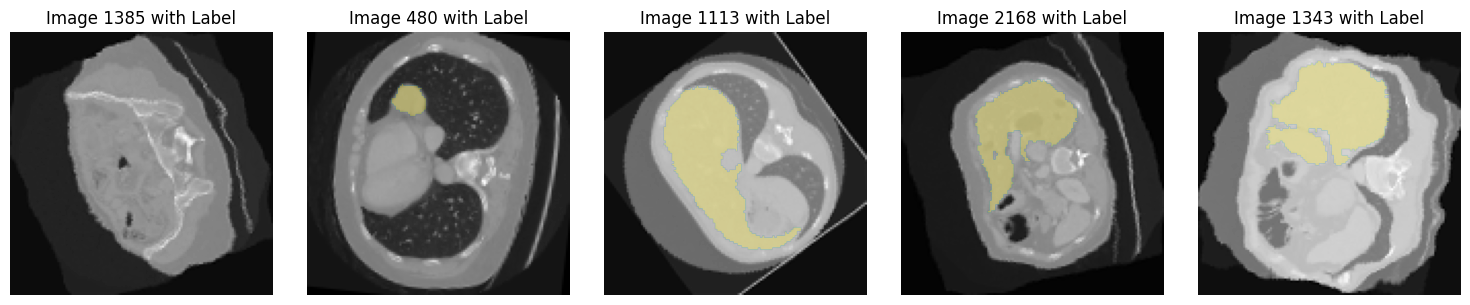

In [17]:
visualize_random_samples(dataset_train, num_samples=5)

#### 7.2 Visualizing Validation Dataset Samples

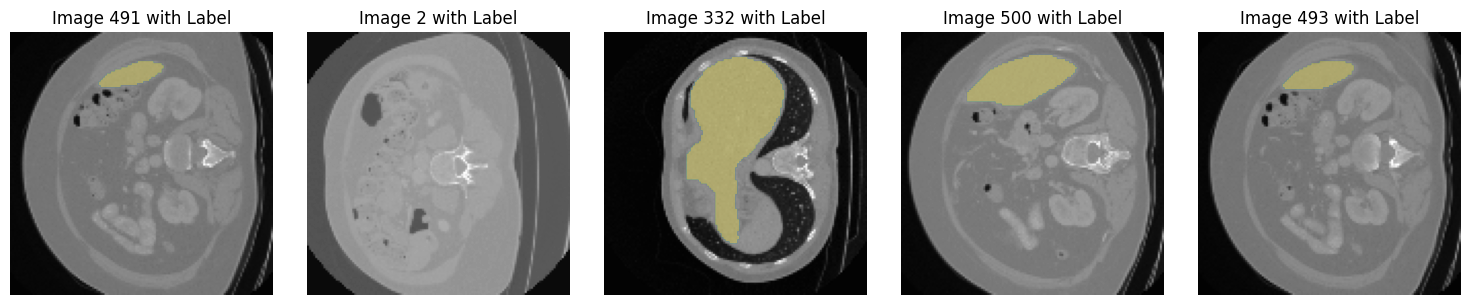

In [14]:
visualize_random_samples(dataset_val, num_samples=5)